# Analytics Report & Insights Documentation
## Reducing Customer Churn at a Telecom Provider – 7,043 customers
**Task 5 – Yuva Intern | AI/ML Research Specialist Internship**

Workflow: **business objectives → data analysis → visualisations & dashboard → business insights → executive summary → recommendations.**

## 1. Business Objectives & Stakeholder Requirements
**Business problem.** A subscription telecom provider is losing customers every month. Each lost customer removes recurring revenue and the cost of acquiring a replacement is much higher than the cost of retaining an existing one.

**Dataset.** IBM's public *Telco Customer Churn* sample dataset: 7,043 customers × 21 columns (demographics, services, contract, billing, monthly and total charges, and whether the customer left in the last month). It is a widely used IBM sample dataset for churn analytics (a simulated company, not real company records), so the conclusions illustrate the method rather than describe a real firm.

| Stakeholder | Key questions | Reporting requirement |
|---|---|---|
| Executive team | How big is the churn problem in revenue terms? What should we do first? | One-page summary with KPIs and prioritised actions |
| Marketing / retention | Which customers are at risk and what do they have in common? | Segment profiles, risk scoring, expected campaign reach |
| Product / pricing | Which contracts, services and prices drive churn? | Statistical evidence with effect sizes |
| Finance | How much monthly recurring revenue (MRR) is at risk? | Quantified revenue impact and scenarios |

**Key questions:** (1) What is the churn rate and the revenue it takes away? (2) Which customer, service, contract and billing factors are significantly related to churn? (3) How strong are the effects once confounding is controlled? (4) Can we predict who will churn well enough to target retention offers? (5) What should the business do and what is it worth?

In [1]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.outliers_influence import variance_inflation_factor
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("images", exist_ok=True)
SEED = 42; rng = np.random.default_rng(SEED); M = {}
f = lambda v: float(np.round(v, 4))
def save(name): plt.tight_layout(); plt.savefig(f"images/{name}.png", dpi=130); plt.show()

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try: raw = pd.read_csv("data/telco_raw.csv")
except FileNotFoundError:
    raw = pd.read_csv(URL); raw.to_csv("data/telco_raw.csv", index=False)
print(raw.shape); raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Preparation & Quality Checks

In [2]:
print("Duplicate rows:", raw.duplicated().sum(), "| duplicate customer IDs:", raw.customerID.duplicated().sum())
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")
missing_tc = raw[raw.TotalCharges.isna()]
print("Missing TotalCharges:", len(missing_tc), "| their tenure values:", missing_tc.tenure.unique(), "-> brand-new customers who have not been billed yet")
M.update(rows=len(raw), cols=raw.shape[1], dups=int(raw.duplicated().sum()), missing_tc=len(missing_tc))

df = raw.copy()
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["churn"] = (df.Churn == "Yes").astype(int)
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for c in service_cols + ["MultipleLines"]:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})   # merge redundant levels
df["SeniorCitizen"] = df.SeniorCitizen.map({0: "No", 1: "Yes"})
df["tenure_band"] = pd.cut(df.tenure, [-1, 12, 24, 48, 72], labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
df["addon_count"] = (df[service_cols[:4]] == "Yes").sum(axis=1)       # security, backup, protection, support
df["auto_pay"] = df.PaymentMethod.str.contains("automatic").map({True: "Yes", False: "No"})
# consistency check: total charges should be roughly tenure x monthly
ratio = (df.TotalCharges / (df.tenure * df.MonthlyCharges)).replace([np.inf, -np.inf], np.nan).dropna()
print(f"TotalCharges / (tenure x MonthlyCharges): median = {ratio.median():.3f}, share within +/-50% = {((ratio > .5) & (ratio < 1.5)).mean():.1%}")
df.to_csv("data/telco_clean.csv", index=False)
print("Missing after cleaning:", int(df.isna().sum().sum()))

Duplicate rows: 0 | duplicate customer IDs: 0
Missing TotalCharges: 11 | their tenure values: [0] -> brand-new customers who have not been billed yet
TotalCharges / (tenure x MonthlyCharges): median = 1.000, share within +/-50% = 100.0%
Missing after cleaning: 0


## 3. Headline KPIs

In [3]:
n = len(df); churned = int(df.churn.sum()); rate = churned / n
lo, hi = proportion_confint(churned, n, method="wilson")
mrr = df.MonthlyCharges.sum(); mrr_lost = df.loc[df.churn == 1, "MonthlyCharges"].sum()
print(f"Customers: {n:,} | churned: {churned:,} | churn rate: {rate:.2%} (95% Wilson CI {lo:.2%}-{hi:.2%})")
print(f"Monthly recurring revenue (MRR): ${mrr:,.0f} | MRR belonging to churned customers: ${mrr_lost:,.0f} ({mrr_lost/mrr:.1%}) -> ${mrr_lost*12:,.0f} per year")
print(f"Average monthly charge: churned ${df[df.churn==1].MonthlyCharges.mean():.2f} vs retained ${df[df.churn==0].MonthlyCharges.mean():.2f}")
print(f"Average tenure: churned {df[df.churn==1].tenure.mean():.1f} months vs retained {df[df.churn==0].tenure.mean():.1f} months")
print(f"Lifetime revenue collected from churned customers: ${df.loc[df.churn==1, 'TotalCharges'].sum():,.0f}")
M.update(n=n, churned=churned, rate=f(rate), ci_lo=f(lo), ci_hi=f(hi), mrr=f(mrr), mrr_lost=f(mrr_lost), mrr_lost_pct=f(mrr_lost / mrr), arr_lost=f(mrr_lost * 12),
         mc_churn=f(df[df.churn == 1].MonthlyCharges.mean()), mc_stay=f(df[df.churn == 0].MonthlyCharges.mean()),
         ten_churn=f(df[df.churn == 1].tenure.mean()), ten_stay=f(df[df.churn == 0].tenure.mean()))

Customers: 7,043 | churned: 1,869 | churn rate: 26.54% (95% Wilson CI 25.52%-27.58%)
Monthly recurring revenue (MRR): $456,117 | MRR belonging to churned customers: $139,131 (30.5%) -> $1,669,570 per year
Average monthly charge: churned $74.44 vs retained $61.27
Average tenure: churned 18.0 months vs retained 37.6 months
Lifetime revenue collected from churned customers: $2,862,927


## 4. Segment Analysis – Where Is Churn Concentrated?

In [4]:
def seg(col):
    g = df.groupby(col, observed=True).agg(customers=("churn", "size"), churned=("churn", "sum"), churn_rate=("churn", "mean"),
                                            mrr=("MonthlyCharges", "sum")).round(4)
    g["share_of_all_churn"] = (g.churned / churned).round(4)
    return g
segs = {}
for col in ["Contract", "InternetService", "PaymentMethod", "tenure_band", "PaperlessBilling", "TechSupport", "OnlineSecurity", "SeniorCitizen", "Partner", "Dependents", "gender", "auto_pay"]:
    segs[col] = seg(col); print(f"--- {col} ---"); print(segs[col].to_string(), "\n")
M["segs"] = {k: v.reset_index().astype({k: str}).to_dict("records") for k, v in segs.items()}

--- Contract ---
                customers  churned  churn_rate        mrr  share_of_all_churn
Contract                                                                     
Month-to-month       3875     1655      0.4271  257294.15              0.8855
One year             1473      166      0.1127   95816.60              0.0888
Two year             1695       48      0.0283  103005.85              0.0257 



--- InternetService ---
                 customers  churned  churn_rate        mrr  share_of_all_churn
InternetService                                                               
DSL                   2421      459      0.1896  140665.35              0.2456
Fiber optic           3096     1297      0.4189  283284.40              0.6940
No                    1526      113      0.0740   32166.85              0.0605 

--- PaymentMethod ---
                           customers  churned  churn_rate        mrr  share_of_all_churn
PaymentMethod                                                                           
Bank transfer (automatic)       1544      258      0.1671  103745.45              0.1380
Credit card (automatic)         1522      232      0.1524  101231.85              0.1241
Electronic check                2365     1071      0.4529  180345.00              0.5730
Mailed check                    1612      308      0.1911   70794.30              0.1648 

--- tenure_band ---
 

--- SeniorCitizen ---
               customers  churned  churn_rate        mrr  share_of_all_churn
SeniorCitizen                                                               
No                  5901     1393      0.2361  364961.75              0.7453
Yes                 1142      476      0.4168   91154.85              0.2547 

--- Partner ---
         customers  churned  churn_rate        mrr  share_of_all_churn
Partner                                                               
No            3641     1200      0.3296  225541.75              0.6421
Yes           3402      669      0.1966  230574.85              0.3579 

--- Dependents ---
            customers  churned  churn_rate        mrr  share_of_all_churn
Dependents                                                               
No               4933     1543      0.3128  330524.85              0.8256
Yes              2110      326      0.1545  125591.75              0.1744 

--- gender ---
        customers  churned  churn_

In [5]:
# Two-way: contract x internet service  (churn rate, customers)
two = df.pivot_table(index="Contract", columns="InternetService", values="churn", aggfunc=["mean", "size"], observed=True).round(3); print(two)
core = df[(df.Contract == "Month-to-month") & (df.tenure <= 12)]
print(f"\nMonth-to-month customers in their first 12 months: {len(core):,} ({len(core)/n:.1%} of base) -> churn {core.churn.mean():.1%}, {core.churn.sum()/churned:.1%} of ALL churn")
M.update(core_n=len(core), core_share=f(len(core) / n), core_rate=f(core.churn.mean()), core_churn_share=f(core.churn.sum() / churned))

                  mean                     size                 
InternetService    DSL Fiber optic     No   DSL Fiber optic   No
Contract                                                        
Month-to-month   0.322       0.546  0.189  1223        2128  524
One year         0.093       0.193  0.025   570         539  364
Two year         0.019       0.072  0.008   628         429  638

Month-to-month customers in their first 12 months: 1,994 (28.3% of base) -> churn 51.4%, 54.8% of ALL churn


## 5. Statistical Testing – Evidence With Numbers
Each test below states the **hypothesis**, shows the **counts or means**, the **test statistic, p-value and an effect size**, and ends with a plain-language **interpretation**. A significance level of α = 0.05 is used, and p-values across the family of chi-square tests are adjusted for multiple comparisons.

### 5.1 Chi-square test of independence – contract type vs churn
**H₀:** churn is independent of contract type. **H₁:** churn rate differs by contract. The table shows observed counts and the counts that would be expected under H₀.

In [6]:
obs = pd.crosstab(df.Contract, df.Churn); chi2, p, dof, exp = stats.chi2_contingency(obs)
print("Observed counts:\n", obs, "\n\nExpected under independence:\n", pd.DataFrame(exp, index=obs.index, columns=obs.columns).round(1))
print("\nChurn rate by contract:\n", (obs["Yes"] / obs.sum(axis=1)).round(4))
V = np.sqrt(chi2 / (obs.values.sum() * (min(obs.shape) - 1)))
print(f"\nchi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramer's V = {V:.3f}")
mm = obs.loc["Month-to-month"]; two_y = obs.loc["Two year"]
rr = (mm["Yes"] / mm.sum()) / (two_y["Yes"] / two_y.sum()); print(f"Relative risk month-to-month vs two-year: {rr:.1f}x")
M.update(ct_obs=obs.reset_index().to_dict("records"), ct_exp=pd.DataFrame(exp, index=obs.index, columns=obs.columns).round(1).reset_index().to_dict("records"),
         ct_chi2=f(chi2), ct_p=float(p), ct_V=f(V), ct_rr=f(rr), ct_dof=int(dof))

Observed counts:
 Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48 

Expected under independence:
 Churn               No     Yes
Contract                      
Month-to-month  2846.7  1028.3
One year        1082.1   390.9
Two year        1245.2   449.8

Churn rate by contract:
 Contract
Month-to-month    0.4271
One year          0.1127
Two year          0.0283
dtype: float64

chi2 = 1184.6, dof = 2, p = 5.86e-258, Cramer's V = 0.410
Relative risk month-to-month vs two-year: 15.1x


**Interpretation:** month-to-month customers churn far more than expected if contract did not matter (and one- and two-year customers far less). The effect is large for a categorical association (Cramér's V = 0.41), and month-to-month customers are about 15 times as likely to churn as two-year customers.

### 5.2 Chi-square tests for every categorical feature, with Holm correction

In [7]:
cats = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
        "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
rows = []
for c in cats:
    t = pd.crosstab(df[c], df.churn); chi, pv, dof_, _ = stats.chi2_contingency(t); v = np.sqrt(chi / (t.values.sum() * (min(t.shape) - 1)))
    rows.append((c, dof_, chi, pv, v))
chi_tab = pd.DataFrame(rows, columns=["feature", "dof", "chi2", "p_raw", "cramers_v"])
chi_tab["p_holm"] = multipletests(chi_tab.p_raw, method="holm")[1]; chi_tab["significant"] = chi_tab.p_holm < 0.05
chi_tab = chi_tab.sort_values("cramers_v", ascending=False).reset_index(drop=True)
pd.set_option("display.float_format", lambda v: f"{v:.4g}"); print(chi_tab.to_string(index=False))
M["chi_tab"] = chi_tab.round(4).to_dict("records"); M["n_sig"] = int(chi_tab.significant.sum()); M["n_tests"] = len(chi_tab)
print(f"\n{M['n_sig']} of {M['n_tests']} features are significantly related to churn after Holm correction.")
print("Not significant:", chi_tab[~chi_tab.significant].feature.tolist())

         feature  dof   chi2      p_raw  cramers_v     p_holm  significant
        Contract    2   1185 5.863e-258     0.4101 9.381e-257         True
 InternetService    2  732.3 9.572e-160     0.3225 1.436e-158         True
   PaymentMethod    3  648.1 3.682e-140     0.3034 5.155e-139         True
PaperlessBilling    1  258.3  4.073e-58     0.1915  5.295e-57         True
  OnlineSecurity    1  205.6  1.232e-46     0.1709  1.479e-45         True
     TechSupport    1  190.2  2.924e-43     0.1643  3.216e-42         True
      Dependents    1  189.1  4.925e-43     0.1639  4.925e-42         True
   SeniorCitizen    1  159.4   1.51e-36     0.1505  1.359e-35         True
         Partner    1  158.7   2.14e-36     0.1501  1.712e-35         True
    OnlineBackup    1  47.26  6.214e-12    0.08192   4.35e-11         True
DeviceProtection    1  30.51  3.316e-08    0.06582  1.989e-07         True
     StreamingTV    1  27.86  1.302e-07     0.0629  6.512e-07         True
 StreamingMovies    1  26

**Interpretation:** statistical significance is not the same as importance – the strength column (Cramér's V) ranks the features. Contract type (V = 0.41), internet service (0.32), payment method (0.30) and paperless billing (0.19) have the strongest associations, followed by online security, tech support, dependents, senior citizen and partner status (V about 0.15-0.17); gender and phone service have effectively none (p > 0.05 even before correction).

### 5.3 Two-proportion z-test – Fibre optic vs DSL
**H₀:** the churn rates of fibre-optic and DSL customers are equal.

In [8]:
fib = df[df.InternetService == "Fiber optic"].churn; dsl = df[df.InternetService == "DSL"].churn
cnt = np.array([fib.sum(), dsl.sum()]); nobs = np.array([len(fib), len(dsl)])
z, pz = proportions_ztest(cnt, nobs); diff_lo, diff_hi = confint_proportions_2indep(cnt[0], nobs[0], cnt[1], nobs[1], method="wald")
print(f"Fibre: {cnt[0]:,} / {nobs[0]:,} = {cnt[0]/nobs[0]:.2%} | DSL: {cnt[1]:,} / {nobs[1]:,} = {cnt[1]/nobs[1]:.2%}")
print(f"Difference = {(cnt[0]/nobs[0] - cnt[1]/nobs[1])*100:.1f} percentage points, 95% CI ({diff_lo*100:.1f}, {diff_hi*100:.1f}) pp")
print(f"z = {z:.2f}, p = {pz:.2e}, Cohen's h = {proportion_effectsize(cnt[0]/nobs[0], cnt[1]/nobs[1]):.3f}")
fm = df[df.InternetService == "Fiber optic"]
print(f"\nWhy? Fibre customers pay ${fm.MonthlyCharges.mean():.2f}/month vs DSL ${df[df.InternetService=='DSL'].MonthlyCharges.mean():.2f}; only "
      f"{(fm.TechSupport=='Yes').mean():.1%} of fibre customers have tech support and {(fm.OnlineSecurity=='Yes').mean():.1%} online security.")
M.update(fib_n=int(nobs[0]), fib_c=int(cnt[0]), dsl_n=int(nobs[1]), dsl_c=int(cnt[1]), fib_rate=f(cnt[0]/nobs[0]), dsl_rate=f(cnt[1]/nobs[1]), z_fd=f(z), p_fd=float(pz),
         diff_lo=f(diff_lo*100), diff_hi=f(diff_hi*100), h_fd=f(proportion_effectsize(cnt[0]/nobs[0], cnt[1]/nobs[1])),
         fib_mc=f(fm.MonthlyCharges.mean()), dsl_mc=f(df[df.InternetService=='DSL'].MonthlyCharges.mean()),
         fib_ts=f((fm.TechSupport == "Yes").mean()), fib_os=f((fm.OnlineSecurity == "Yes").mean()))

Fibre: 1,297 / 3,096 = 41.89% | DSL: 459 / 2,421 = 18.96%
Difference = 22.9 percentage points, 95% CI (20.6, 25.3) pp
z = 18.15, p = 1.35e-73, Cohen's h = 0.507

Why? Fibre customers pay $91.50/month vs DSL $58.10; only 28.0% of fibre customers have tech support and 27.1% online security.


### 5.4 Welch t-test, Mann-Whitney and effect size – tenure of churned vs retained customers

In [9]:
a = df[df.churn == 1].tenure; b = df[df.churn == 0].tenure
t, pt = stats.ttest_ind(a, b, equal_var=False); u, pu = stats.mannwhitneyu(a, b)
sp = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2)); d = (a.mean() - b.mean()) / sp
se = np.sqrt(a.var()/len(a) + b.var()/len(b)); dfw = se**4 / ((a.var()/len(a))**2/(len(a)-1) + (b.var()/len(b))**2/(len(b)-1))
ci = (a.mean()-b.mean() + np.array([-1, 1]) * stats.t.ppf(.975, dfw) * se)
print(f"Churned: mean {a.mean():.2f} m, median {a.median():.0f} m (n={len(a):,}) | Retained: mean {b.mean():.2f} m, median {b.median():.0f} m (n={len(b):,})")
print(f"Welch t = {t:.2f}, p = {pt:.2e}; difference = {a.mean()-b.mean():.2f} months, 95% CI ({ci[0]:.2f}, {ci[1]:.2f})")
print(f"Mann-Whitney U = {u:,.0f}, p = {pu:.2e}; Cohen's d = {d:.2f}")
sh = stats.shapiro(df.tenure.sample(5000, random_state=SEED)); print(f"Shapiro-Wilk on tenure: W = {sh.statistic:.3f} (not normal -> Mann-Whitney is the safer confirmation)")
M.update(t_ten=f(t), p_ten=float(pt), ten_diff=f(a.mean() - b.mean()), ten_ci_lo=f(ci[0]), ten_ci_hi=f(ci[1]), U_ten=f(u), d_ten=f(d), ten_med_c=f(a.median()), ten_med_s=f(b.median()))

Churned: mean 17.98 m, median 10 m (n=1,869) | Retained: mean 37.57 m, median 38 m (n=5,174)
Welch t = -34.82, p = 1.20e-232; difference = -19.59 months, 95% CI (-20.69, -18.49)
Mann-Whitney U = 2,515,538, p = 2.42e-208; Cohen's d = -0.85
Shapiro-Wilk on tenure: W = 0.903 (not normal -> Mann-Whitney is the safer confirmation)


In [10]:
a = df[df.churn == 1].MonthlyCharges; b = df[df.churn == 0].MonthlyCharges
t, pt = stats.ttest_ind(a, b, equal_var=False); sp = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2)); d = (a.mean() - b.mean()) / sp
print(f"Monthly charges: churned ${a.mean():.2f} vs retained ${b.mean():.2f}; Welch t = {t:.2f}, p = {pt:.2e}, Cohen's d = {d:.2f}")
M.update(t_mc=f(t), p_mc=float(pt), d_mc=f(d))

Monthly charges: churned $74.44 vs retained $61.27; Welch t = 18.41, p = 8.59e-73, Cohen's d = 0.45


**Interpretation:** churned customers have a much shorter tenure (a large effect, |d| > 0.8) and pay a higher monthly price (a medium effect, d about 0.45). Tenure separates the groups much more strongly than price does.

### 5.5 One-way ANOVA and Kruskal-Wallis – monthly charges across contract types
Tests whether average monthly charges differ between the three contract types (a possible confounder: if long contracts were cheaper, price might explain the contract effect).

In [11]:
groups = [g.MonthlyCharges.to_numpy() for _, g in df.groupby("Contract")]
F, pa = stats.f_oneway(*groups); H, pk = stats.kruskal(*groups)
grand = df.MonthlyCharges.mean(); eta2 = sum(len(g)*(g.mean()-grand)**2 for g in groups) / ((df.MonthlyCharges - grand)**2).sum()
print(df.groupby("Contract").MonthlyCharges.agg(["count", "mean", "median", "std"]).round(2))
print(f"\nANOVA F = {F:.1f}, p = {pa:.2e}, eta^2 = {eta2:.4f} | Kruskal-Wallis H = {H:.1f}, p = {pk:.2e}")
tk = stats.tukey_hsd(*groups); names = [k for k, _ in df.groupby("Contract")]
for i in range(3):
    for j in range(i+1, 3): print(f"  Tukey {names[i]} vs {names[j]}: mean diff = {groups[i].mean()-groups[j].mean():+.2f}, p = {tk.pvalue[i, j]:.3g}")
M.update(anova_F=f(F), anova_p=float(pa), eta2_mc=f(eta2), kw_H=f(H), mc_by_contract=df.groupby("Contract").MonthlyCharges.agg(["count", "mean", "median", "std"]).round(2).reset_index().to_dict("records"))

                count  mean  median   std
Contract                                 
Month-to-month   3875  66.4   73.25 26.93
One year         1473 65.05   68.75 31.84
Two year         1695 60.77   64.35 34.68

ANOVA F = 20.8, p = 9.58e-10, eta^2 = 0.0059 | Kruskal-Wallis H = 21.2, p = 2.46e-05
  Tukey Month-to-month vs One year: mean diff = +1.35, p = 0.306
  Tukey Month-to-month vs Two year: mean diff = +5.63, p = 3.8e-10
  Tukey One year vs Two year: mean diff = +4.28, p = 0.000187


### 5.6 Correlation analysis

In [12]:
r1, p1 = stats.pearsonr(df.tenure, df.TotalCharges); s1, _ = stats.spearmanr(df.tenure, df.TotalCharges)
r2, p2 = stats.pearsonr(df.tenure, df.MonthlyCharges); r3, p3 = stats.pointbiserialr(df.churn, df.tenure); r4, p4 = stats.pointbiserialr(df.churn, df.MonthlyCharges)
print(f"tenure vs TotalCharges   : Pearson r = {r1:.3f}, Spearman rho = {s1:.3f}")
print(f"tenure vs MonthlyCharges : Pearson r = {r2:.3f} (weak -> long-tenure customers do not simply pay more)")
print(f"churn vs tenure          : point-biserial r = {r3:.3f}  (p = {p3:.1e})")
print(f"churn vs MonthlyCharges  : point-biserial r = {r4:.3f}  (p = {p4:.1e})")
X = sm.add_constant(df[["tenure", "MonthlyCharges", "TotalCharges"]]); vif = {c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != "const"}
print("VIF:", {k: round(v, 1) for k, v in vif.items()}, "-> TotalCharges has the highest VIF because it is roughly tenure x monthly charges, so it is excluded from the regression")
M.update(r_ten_tc=f(r1), s_ten_tc=f(s1), r_ten_mc=f(r2), r_churn_ten=f(r3), r_churn_mc=f(r4), vif={k: f(v) for k, v in vif.items()})

tenure vs TotalCharges   : Pearson r = 0.826, Spearman rho = 0.890
tenure vs MonthlyCharges : Pearson r = 0.248 (weak -> long-tenure customers do not simply pay more)
churn vs tenure          : point-biserial r = -0.352  (p = 8.0e-205)
churn vs MonthlyCharges  : point-biserial r = 0.193  (p = 2.7e-60)
VIF: {'tenure': np.float64(5.8), 'MonthlyCharges': np.float64(3.2), 'TotalCharges': np.float64(9.5)} -> TotalCharges has the highest VIF because it is roughly tenure x monthly charges, so it is excluded from the regression


### 5.7 Logistic regression – effect of each factor with the others held constant
Chi-square tests look at one factor at a time and can be confounded (fibre customers are also higher-paying, more often month-to-month…). A multivariate logistic regression estimates the **odds ratio (OR)** of churn for each factor *holding the others constant*. OR > 1 raises churn odds; OR < 1 lowers them.

In [13]:
form = ("churn ~ tenure + MonthlyCharges + C(Contract, Treatment('Month-to-month')) + C(InternetService, Treatment('DSL')) + C(PaymentMethod, Treatment('Mailed check'))"
        " + C(PaperlessBilling) + C(TechSupport) + C(OnlineSecurity) + C(SeniorCitizen) + C(Partner) + C(Dependents)")
lr = smf.logit(form, data=df).fit(disp=0)
print(f"n = {int(lr.nobs):,}, pseudo R2 (McFadden) = {lr.prsquared:.3f}, LLR p = {lr.llr_pvalue:.2e}")
rename = lambda s: (s.replace("C(Contract, Treatment('Month-to-month'))[T.", "Contract: ").replace("C(InternetService, Treatment('DSL'))[T.", "Internet: ")
                     .replace("C(PaymentMethod, Treatment('Mailed check'))[T.", "Payment: ").replace("C(", "").replace(")[T.", ": ").replace("]", ""))
orx = pd.DataFrame({"OR": np.exp(lr.params), "CI_low": np.exp(lr.conf_int()[0]), "CI_high": np.exp(lr.conf_int()[1]), "p": lr.pvalues}).drop("Intercept")
orx.index = [rename(i) for i in orx.index]; orx = orx.sort_values("OR", ascending=False).round(3); print(orx.to_string())
M.update(lr_prsq=f(lr.prsquared), lr_n=int(lr.nobs), orx=orx.reset_index().rename(columns={"index": "factor"}).to_dict("records"))
print(f"\nOne extra month of tenure multiplies churn odds by {np.exp(lr.params['tenure']):.3f} (a {(1-np.exp(lr.params['tenure']))*100:.1f}% reduction per month; "
      f"{(1-np.exp(12*lr.params['tenure']))*100:.0f}% per year)")
M["or_ten_month"] = f(np.exp(lr.params["tenure"])); M["or_ten_year_red"] = f((1 - np.exp(12 * lr.params["tenure"])) * 100)

n = 7,043, pseudo R2 (McFadden) = 0.275, LLR p = 0.00e+00
                                      OR  CI_low  CI_high     p
Internet: Fiber optic              1.661   1.261    2.188     0
Payment: Electronic check          1.468    1.22    1.767     0
PaperlessBilling: Yes              1.449   1.254    1.674     0
SeniorCitizen: Yes                 1.283   1.088    1.513 0.003
Payment: Bank transfer (automatic) 1.026   0.822    1.279 0.823
Partner: Yes                       1.012    0.87    1.177  0.88
MonthlyCharges                     1.011   1.005    1.018 0.001
tenure                             0.969   0.965    0.973     0
Payment: Credit card (automatic)   0.945   0.755    1.184 0.624
Dependents: Yes                    0.831   0.697    0.989 0.037
TechSupport: Yes                   0.679   0.571    0.807     0
OnlineSecurity: Yes                0.635   0.537     0.75     0
Contract: One year                 0.516   0.419    0.635     0
Internet: No                       0.464   0.3

**Interpretation:** after controlling for the other factors, contract length and tenure remain the dominant protective factors, fibre-optic internet, electronic-check payment (relative to mailed check) and paperless billing remain risk factors, and tech support / online security remain protective. The odds ratio for monthly charges is only about 1.011 per dollar, but compounds across a $20 price difference (1.011^20 = 1.24). Notably, automatic bank-transfer and credit-card payment are *not* different from mailed check once other factors are held constant – the specific risk is electronic check.

### 5.8 Bootstrap confidence intervals and a power analysis for a retention test
**Bootstrap** gives uncertainty bounds for the churn-rate gap between month-to-month and long-contract customers. A **power analysis** says how many customers a pilot would need to detect a realistic improvement.

In [14]:
mtm = df[df.Contract == "Month-to-month"].churn.to_numpy(); long = df[df.Contract != "Month-to-month"].churn.to_numpy()
boot = np.array([rng.choice(mtm, len(mtm)).mean() - rng.choice(long, len(long)).mean() for _ in range(2000)])
bl, bh = np.percentile(boot, [2.5, 97.5])
print(f"Churn rate month-to-month {mtm.mean():.2%} vs 1-/2-year {long.mean():.2%}; gap = {(mtm.mean()-long.mean())*100:.1f} pp, bootstrap 95% CI ({bl*100:.1f}, {bh*100:.1f}) pp")
base = mtm.mean(); target = base - 0.05; es = proportion_effectsize(base, target)
n_per = NormalIndPower().solve_power(effect_size=es, alpha=0.05, power=0.80, ratio=1, alternative="two-sided")
print(f"Pilot design: to detect a drop in churn from {base:.1%} to {target:.1%} (5 pp) with 80% power at alpha = 0.05 needs {int(np.ceil(n_per)):,} customers per group")
M.update(boot_gap=f((mtm.mean() - long.mean()) * 100), boot_lo=f(bl * 100), boot_hi=f(bh * 100), mtm_rate=f(base), long_rate=f(long.mean()), pilot_n=int(np.ceil(n_per)), mtm_n=len(mtm), long_n=len(long))

Churn rate month-to-month 42.71% vs 1-/2-year 6.76%; gap = 36.0 pp, bootstrap 95% CI (34.2, 37.8) pp
Pilot design: to detect a drop in churn from 42.7% to 37.7% (5 pp) with 80% power at alpha = 0.05 needs 1,509 customers per group


## 6. Predictive Risk Scoring (to target retention offers)

In [15]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, confusion_matrix, average_precision_score

num = ["tenure", "MonthlyCharges", "addon_count"]; cat = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "TechSupport", "OnlineSecurity",
                                                       "SeniorCitizen", "Partner", "Dependents", "StreamingTV", "StreamingMovies", "MultipleLines", "OnlineBackup", "DeviceProtection"]
X = df[num + cat]; y = df.churn
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
pre = lambda: ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
models = {"Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
          "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=SEED),
          "Gradient Boosting": GradientBoostingClassifier(random_state=SEED)}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED); rows = []; fitted = {}
for nme, m in models.items():
    pipe = Pipeline([("p", pre()), ("m", m)]); cv = cross_val_score(pipe, Xtr, ytr, cv=skf, scoring="roc_auc"); pipe.fit(Xtr, ytr); fitted[nme] = pipe
    pr = pipe.predict_proba(Xte)[:, 1]; rows.append((nme, cv.mean(), cv.std(), roc_auc_score(yte, pr), average_precision_score(yte, pr)))
res = pd.DataFrame(rows, columns=["model", "cv_auc", "cv_std", "test_auc", "test_avg_precision"]).round(4); print(res.to_string(index=False))
M["models"] = res.to_dict("records"); M["train_n"] = len(Xtr); M["test_n"] = len(Xte); M["test_base"] = f(yte.mean())

              model  cv_auc  cv_std  test_auc  test_avg_precision
Logistic Regression  0.8427  0.0152    0.8441               0.632
      Random Forest  0.8416  0.0149    0.8401              0.6319
  Gradient Boosting  0.8455  0.0147    0.8451              0.6446


In [16]:
best = fitted["Logistic Regression"]; pr = best.predict_proba(Xte)[:, 1]
test = Xte.assign(y=yte.values, p=pr, mc=df.loc[Xte.index, "MonthlyCharges"].values)
test["decile"] = pd.qcut(test.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = test.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"), churn_rate=("y", "mean")).round(3)
lift["lift"] = (lift.churn_rate / yte.mean()).round(2); lift["cum_capture_%"] = (lift.churners.cumsum() / yte.sum() * 100).round(1); print(lift)
thr = np.quantile(pr, 0.8); flag = pr >= thr
print(f"\nContacting the top 20% highest-risk customers ({flag.sum():,} of {len(yte):,}): precision = {precision_score(yte, flag):.1%}, recall = {recall_score(yte, flag):.1%} of all churners")
M.update(lift=lift.reset_index().astype({"decile": int}).to_dict("records"), top20_prec=f(precision_score(yte, flag)), top20_rec=f(recall_score(yte, flag)),
         top10_lift=float(lift.lift.iloc[0]), top20_capture=float(lift["cum_capture_%"].iloc[1]))
# business scenario – clearly an ASSUMPTION-based illustration
save_rate = 0.20; contacted_mc = test.loc[flag & (test.y == 1), "mc"].sum()
print(f"Illustration: if a retention offer saves {save_rate:.0%} of the churners reached, MRR retained in this test set = ${contacted_mc*save_rate:,.0f}/month "
      f"({contacted_mc*save_rate/test[test.y==1].mc.sum():.1%} of all churned MRR in the test set)")
M.update(sc_save=save_rate, sc_mrr=f(contacted_mc * save_rate), sc_pct=f(contacted_mc * save_rate / test[test.y == 1].mc.sum()))

        customers  churners  churn_rate  lift  cum_capture_%
decile                                                      
1             177       129       0.729  2.75           27.6
2             176       108       0.614  2.32           50.7
3             176        74        0.42  1.58           66.6
4             176        58        0.33  1.24             79
5             176        41       0.233  0.88           87.8
6             176        30        0.17  0.64           94.2
7             176        17       0.097  0.37           97.9
8             176         8       0.045  0.17           99.6
9             176         0           0     0           99.6
10            176         2       0.011  0.04            100

Contacting the top 20% highest-risk customers (353 of 1,761): precision = 67.1%, recall = 50.7% of all churners
Illustration: if a retention offer saves 20% of the churners reached, MRR retained in this test set = $3,896/month (11.4% of all churned MRR in the test se

## 7. Visualisations & Dashboard

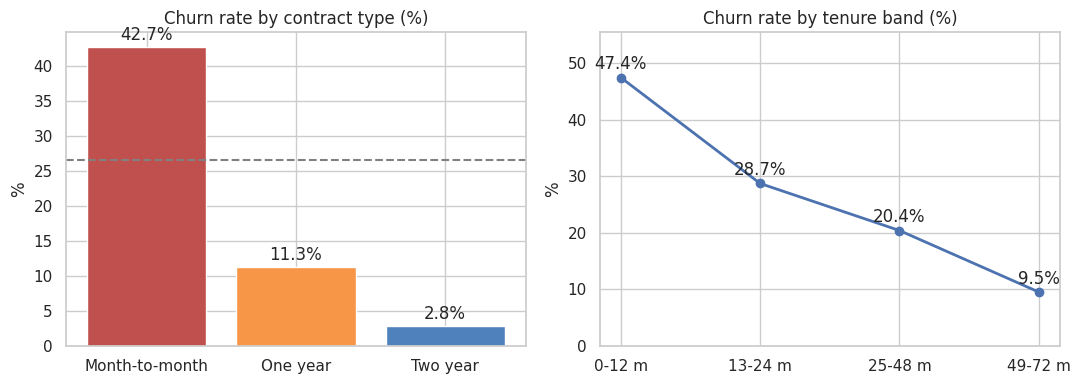

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
c = segs["Contract"].churn_rate * 100; ax[0].bar(c.index, c.values, color=["#c0504d", "#f79646", "#4f81bd"]); ax[0].axhline(rate*100, ls="--", c="gray")
ax[0].set(title="Churn rate by contract type (%)", ylabel="%"); [ax[0].text(i, v + 1, f"{v:.1f}%", ha="center") for i, v in enumerate(c.values)]
t = segs["tenure_band"].churn_rate * 100; ax[1].plot(t.index.astype(str), t.values, marker="o", lw=2); ax[1].set(title="Churn rate by tenure band (%)", ylabel="%")
[ax[1].text(i, v + 1.5, f"{v:.1f}%", ha="center") for i, v in enumerate(t.values)]; ax[1].set_ylim(0, max(t.values) + 8)
save("01_churn_contract_tenure")

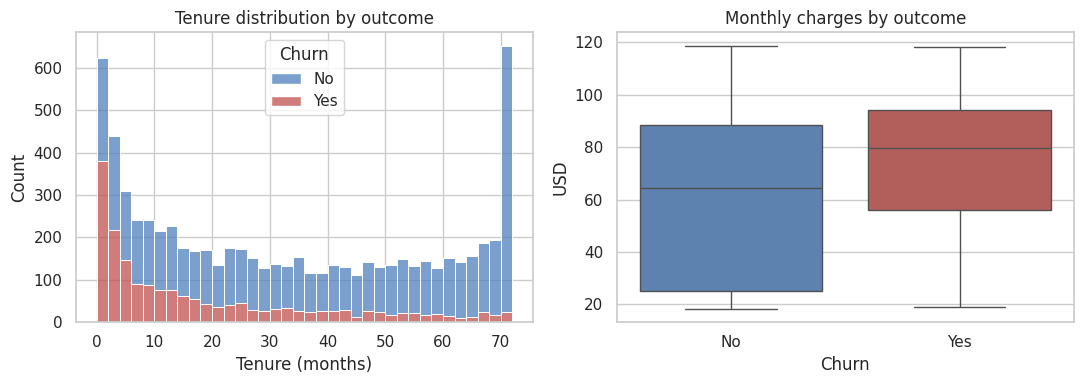

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=ax[0], palette={"No": "#4f81bd", "Yes": "#c0504d"}).set(title="Tenure distribution by outcome", xlabel="Tenure (months)")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", legend=False, ax=ax[1], palette={"No": "#4f81bd", "Yes": "#c0504d"}).set(title="Monthly charges by outcome", ylabel="USD")
save("02_tenure_charges")

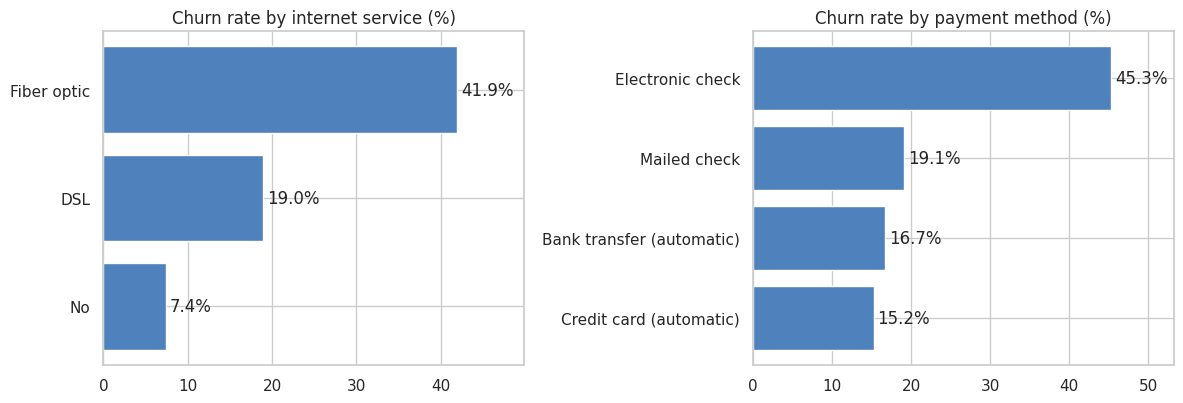

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, col, ttl in [(ax[0], "InternetService", "Churn rate by internet service (%)"), (ax[1], "PaymentMethod", "Churn rate by payment method (%)")]:
    s = (segs[col].churn_rate * 100).sort_values(); a.barh(s.index, s.values, color="#4f81bd"); a.set_title(ttl)
    [a.text(v + .5, i, f"{v:.1f}%", va="center") for i, v in enumerate(s.values)]; a.set_xlim(0, s.max() + 8)
save("03_churn_internet_payment")

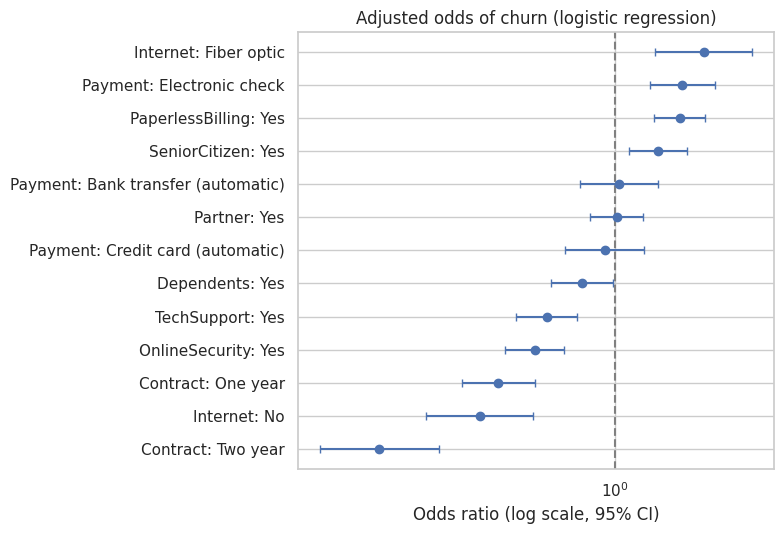

In [20]:
o = orx.drop(index=[i for i in orx.index if "MonthlyCharges" in i or "tenure" in i]).sort_values("OR")
plt.figure(figsize=(8, 5.5)); plt.errorbar(o.OR, range(len(o)), xerr=[o.OR - o.CI_low, o.CI_high - o.OR], fmt="o", capsize=3); plt.axvline(1, c="gray", ls="--")
plt.yticks(range(len(o)), o.index); plt.xscale("log"); plt.xlabel("Odds ratio (log scale, 95% CI)"); plt.title("Adjusted odds of churn (logistic regression)")
save("04_odds_ratios")

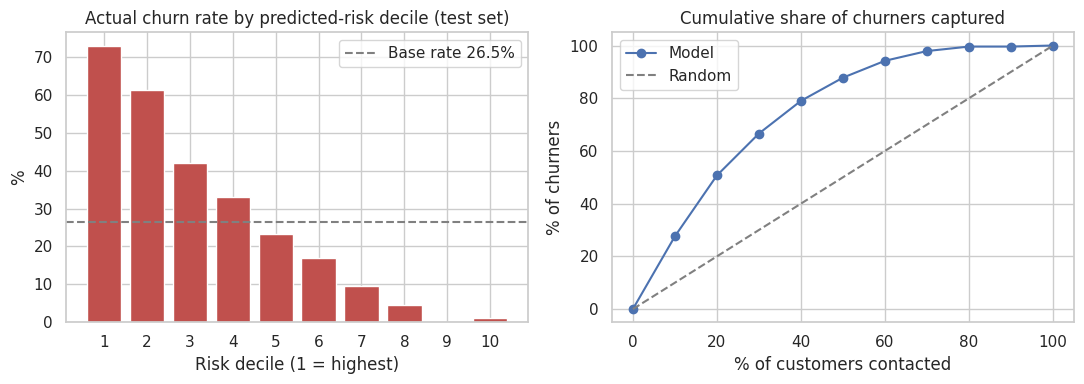

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(lift.index.astype(str), lift.churn_rate * 100, color="#c0504d"); ax[0].axhline(yte.mean() * 100, ls="--", c="gray", label=f"Base rate {yte.mean():.1%}")
ax[0].set(title="Actual churn rate by predicted-risk decile (test set)", xlabel="Risk decile (1 = highest)", ylabel="%"); ax[0].legend()
ax[1].plot([0] + list(range(10, 101, 10)), [0] + lift["cum_capture_%"].tolist(), marker="o", label="Model"); ax[1].plot([0, 100], [0, 100], "--", c="gray", label="Random")
ax[1].set(title="Cumulative share of churners captured", xlabel="% of customers contacted", ylabel="% of churners"); ax[1].legend()
save("05_lift_capture")

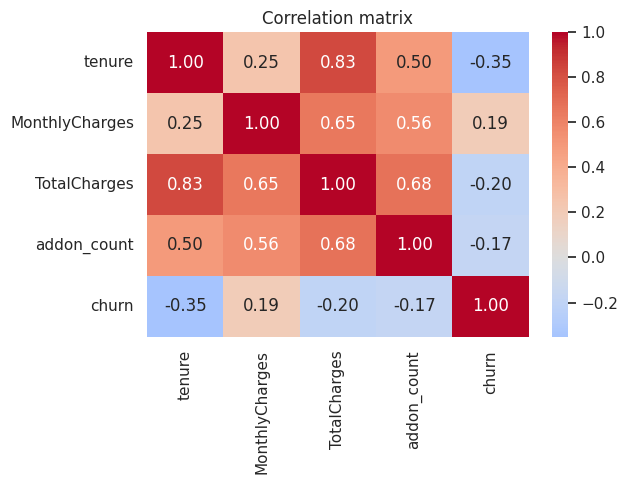

In [22]:
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "addon_count", "churn"]].corr()
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Correlation matrix"); save("06_correlation")

### Executive dashboard (single-page view for stakeholders)

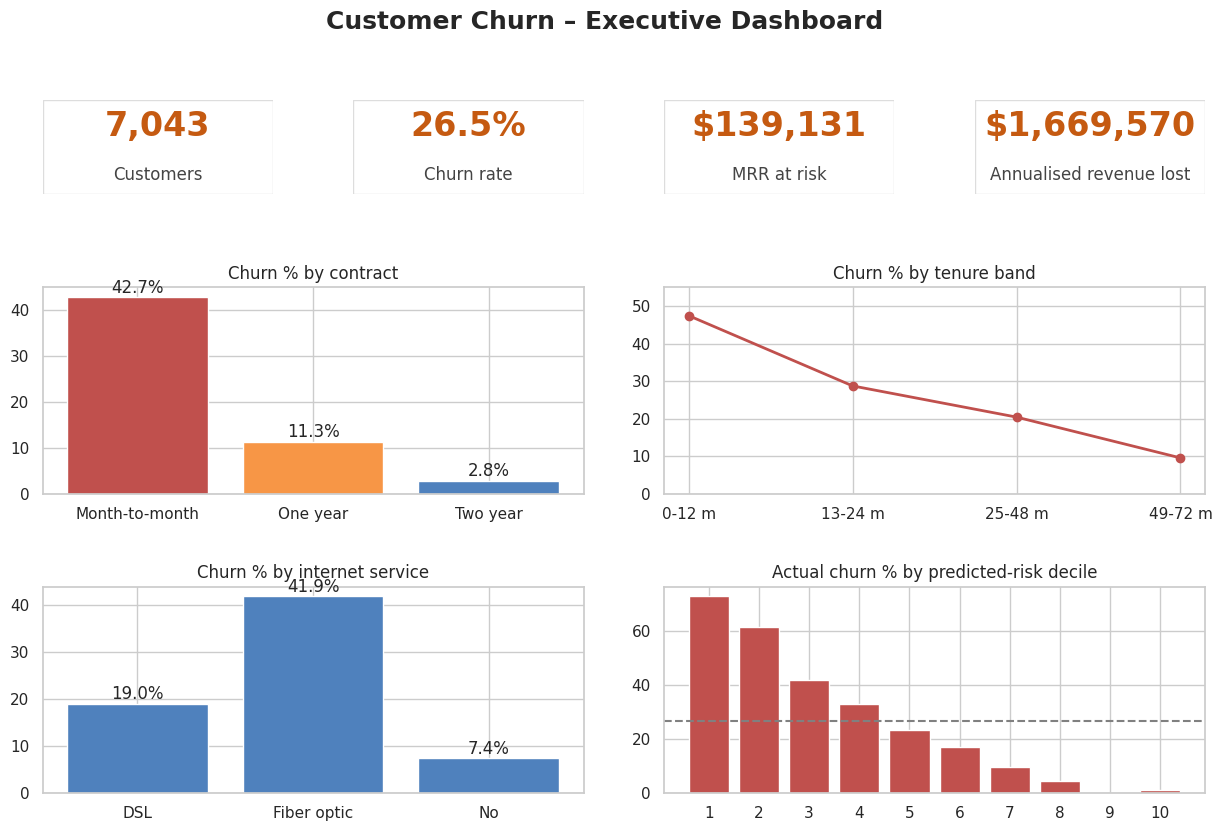

In [23]:
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(15, 9)); gs = GridSpec(3, 4, figure=fig, height_ratios=[0.55, 1.2, 1.2], hspace=0.55, wspace=0.35)
kpis = [("Customers", f"{n:,}"), ("Churn rate", f"{rate:.1%}"), ("MRR at risk", f"${mrr_lost:,.0f}"), ("Annualised revenue lost", f"${mrr_lost*12:,.0f}")]
for i, (k, v) in enumerate(kpis):
    a = fig.add_subplot(gs[0, i]); a.axis("off"); a.text(.5, .62, v, ha="center", fontsize=24, weight="bold", color="#c55a11"); a.text(.5, .15, k, ha="center", fontsize=12, color="#444")
    a.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="#ddd", transform=a.transAxes))
a = fig.add_subplot(gs[1, 0:2]); c = segs["Contract"].churn_rate * 100; a.bar(c.index, c.values, color=["#c0504d", "#f79646", "#4f81bd"]); a.set_title("Churn % by contract"); [a.text(i, v + 1, f"{v:.1f}%", ha="center") for i, v in enumerate(c.values)]
a = fig.add_subplot(gs[1, 2:4]); a.plot(t.index.astype(str), t.values, marker="o", lw=2, c="#c0504d"); a.set_title("Churn % by tenure band"); a.set_ylim(0, 55)
a = fig.add_subplot(gs[2, 0:2]); s = (segs["InternetService"].churn_rate * 100); a.bar(s.index, s.values, color="#4f81bd"); a.set_title("Churn % by internet service"); [a.text(i, v + 1, f"{v:.1f}%", ha="center") for i, v in enumerate(s.values)]
a = fig.add_subplot(gs[2, 2:4]); a.bar(lift.index.astype(str), lift.churn_rate * 100, color="#c0504d"); a.axhline(yte.mean() * 100, ls="--", c="gray"); a.set_title("Actual churn % by predicted-risk decile")
fig.suptitle("Customer Churn – Executive Dashboard", fontsize=18, weight="bold", y=0.98); save("00_dashboard")

## 8. Business Insights

In [24]:
cm = segs["Contract"]; ps = segs["PaymentMethod"]; ts = segs["TechSupport"]
print(f"1. SCALE: {rate:.1%} of customers churned, taking ${mrr_lost:,.0f} of monthly revenue ({mrr_lost/mrr:.1%} of MRR) = ${mrr_lost*12:,.0f} a year.")
print(f"2. CONTRACT: month-to-month churn is {cm.loc['Month-to-month','churn_rate']:.1%} vs {cm.loc['Two year','churn_rate']:.1%} on two-year contracts (relative risk {M['ct_rr']:.1f}x); month-to-month customers produce {cm.loc['Month-to-month','share_of_all_churn']:.1%} of all churn.")
print(f"3. EARLY LIFE: customers in their first 12 months churn at {segs['tenure_band'].loc['0-12 m','churn_rate']:.1%}; the month-to-month + first-year group is {M['core_share']:.1%} of customers but {M['core_churn_share']:.1%} of all churn.")
print(f"4. FIBRE: {M['fib_rate']:.1%} churn vs DSL {M['dsl_rate']:.1%}; fibre customers pay ${M['fib_mc']:.0f}/month yet only {M['fib_ts']:.0%} have tech support.")
print(f"5. SUPPORT/SECURITY: churn without tech support {ts.loc['No','churn_rate']:.1%} vs with {ts.loc['Yes','churn_rate']:.1%}.")
print(f"6. PAYMENT: electronic-check customers churn at {ps.loc['Electronic check','churn_rate']:.1%}; automatic payment methods at {segs['auto_pay'].loc['Yes','churn_rate']:.1%}.")
print(f"7. TARGETING: the model's top 10% risk decile churns at {lift.churn_rate.iloc[0]:.1%} ({M['top10_lift']:.1f}x the base rate); contacting the top 20% reaches {M['top20_capture']:.1f}% of churners.")

1. SCALE: 26.5% of customers churned, taking $139,131 of monthly revenue (30.5% of MRR) = $1,669,570 a year.
2. CONTRACT: month-to-month churn is 42.7% vs 2.8% on two-year contracts (relative risk 15.1x); month-to-month customers produce 88.5% of all churn.
3. EARLY LIFE: customers in their first 12 months churn at 47.4%; the month-to-month + first-year group is 28.3% of customers but 54.8% of all churn.
4. FIBRE: 41.9% churn vs DSL 19.0%; fibre customers pay $92/month yet only 28% have tech support.
5. SUPPORT/SECURITY: churn without tech support 31.2% vs with 15.2%.
6. PAYMENT: electronic-check customers churn at 45.3%; automatic payment methods at 16.0%.
7. TARGETING: the model's top 10% risk decile churns at 72.9% (2.8x the base rate); contacting the top 20% reaches 50.7% of churners.


## 9. Executive Summary
**Objective.** Understand why customers leave a telecom provider, quantify the revenue impact and recommend actions.

**Major findings.** Churn is concentrated, not random. It is driven mainly by short contracts and short tenure, then by fibre-optic service without support add-ons, and by electronic-check billing. Demographics such as gender are irrelevant.

**Key metrics.** See §3 and the dashboard – churn rate, MRR at risk, annualised revenue lost.

**Conclusion.** A small, identifiable group (new month-to-month customers) accounts for a disproportionate share of lost revenue, and a simple model can find high-risk customers: the top risk decile churns at 2.75× the base rate.

## 10. Recommendations
| Priority | Action | Evidence | Expected impact (illustrative) |
|---|---|---|---|
| 1 | Offer incentives to move month-to-month customers to 1-year contracts, starting in months 1–12 | Contract is the strongest factor (§5.1, §5.7) | Close part of the churn-rate gap shown in §5.8 |
| 2 | Onboarding programme for first-year customers (welcome call, 90-day check-in) | Churn is highest in the first 12 months (§4) | Targets the segment with the largest share of churn |
| 3 | Bundle tech support / online security free for 3–6 months for fibre customers | Fibre churn gap (§5.3) and protective effect of add-ons (§5.7) | Test first – see pilot design |
| 4 | Investigate the electronic-check experience (failed payments, billing disputes) and offer alternatives to its 2,365 users | Electronic check OR = 1.47 vs mailed check (§5.7); autopay vs mailed check shows no difference | Diagnose before spending – it is a risk marker, not proven cause |
| 5 | Run the risk model monthly and contact the top 20% highest-risk customers | Lift table (§6) | Reaches a large share of churners with 20% of the effort |

**Next steps.** Run a randomised pilot (size from the power analysis in §5.8) before roll-out, track churn and MRR monthly, and refresh the model quarterly. Statistical associations here are not proof of causation, which is why a controlled pilot is recommended.

**Limitations.** The dataset is a snapshot of one month's churn from an IBM sample dataset (not real company data); there is no time dimension, no acquisition-cost or margin data, and the scenario in §6 relies on an assumed 20% save rate.

In [25]:
json.dump(M, open("data/metrics.json", "w"), indent=1, default=float); print("metrics.json saved:", len(M), "entries")

metrics.json saved: 95 entries
